Exercise 1
Gel electrophoresis is an analysis method used in all disciplines of the life sciences. The results of gel electrophoresis indicate the relative sizes of the fragments, which is useful for restriction mapping and for analyzing PCR fragments.
1. Take an arbitrary DNA sequence from NCBI (National Center for Biotechnology Information), between 1000 and 3000 nucleotides (letters).
2. Take 10 random samples from this sequence, between 100 and 3000 bases.
3. Store these samples in an array.
4. Simulate the migration of these DNA segments on the electrophoresis gel, based on their molecular weight (number of nucleotides).
Note: Short DNA fragments meet small friction forces and travel fast through the electrophoresis gel, while long DNA fragments exhibit a high friction force and travel slowly through the gel.

Sequence length: 2000 nt
Sample  1: 1762 bp
Sample  2: 1995 bp
Sample  3:  649 bp
Sample  4: 1734 bp
Sample  5: 1452 bp
Sample  6: 1077 bp
Sample  7: 1551 bp
Sample  8:  287 bp
Sample  9:  755 bp
Sample 10: 1143 bp


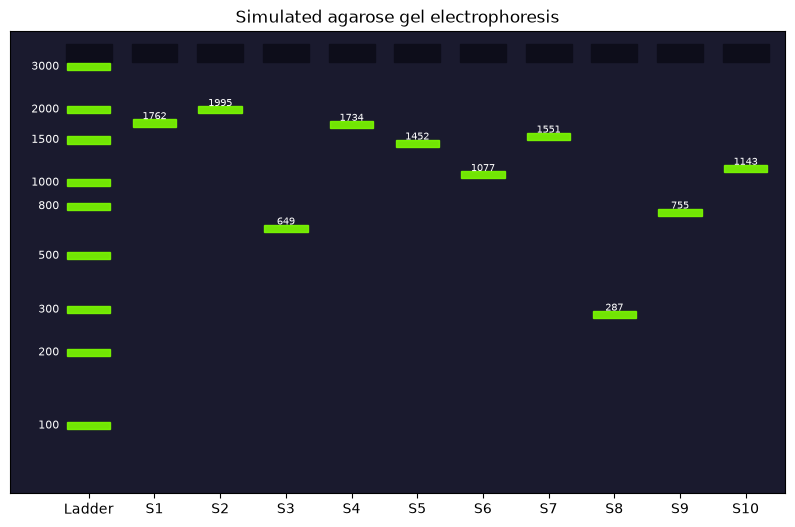

In [3]:
import random
import numpy as np
import matplotlib.pyplot as plt

FASTA_PATH = "ecoli_cft073.fasta"
SEQ_LEN = 2000          # arbitrary NCBI sequence length (1000-3000)
N_SAMPLES = 10
MIN_LEN, MAX_LEN = 100, 3000

def read_fasta(path):
    with open(path) as f:
        return "".join(l.strip() for l in f if not l.startswith(">")).upper()

genome = read_fasta(FASTA_PATH)
start = random.randint(0, len(genome) - SEQ_LEN)
dna = genome[start:start + SEQ_LEN]
print(f"Sequence length: {len(dna)} nt")

samples = []
for _ in range(N_SAMPLES):
    length = random.randint(MIN_LEN, min(MAX_LEN, len(dna)))
    s = random.randint(0, len(dna) - length)
    samples.append(dna[s:s + length])
for i, s in enumerate(samples, 1):
    print(f"Sample {i:2d}: {len(s):4d} bp")

LADDER = [100, 200, 300, 500, 800, 1000, 1500, 2000, 3000]
GEL_HEIGHT = 10.0

def migration(length, lo=MIN_LEN, hi=MAX_LEN):
    # shortest fragment travels the farthest, longest the least
    frac = (np.log10(hi) - np.log10(length)) / (np.log10(hi) - np.log10(lo))
    return 1.0 + frac * (GEL_HEIGHT - 2.0)

lanes = [("Ladder", LADDER)] + [(f"S{i}", [len(s)]) for i, s in enumerate(samples, 1)]

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_facecolor("#1a1a2e")
for x, (name, lengths) in enumerate(lanes):
    ax.add_patch(plt.Rectangle((x - 0.35, 0.5), 0.7, 0.4, color="#0d0d1a"))  # well
    for L in lengths:
        y = migration(L)
        ax.add_patch(plt.Rectangle((x - 0.33, y - 0.08), 0.66, 0.16, color="#7CFC00", alpha=0.9))
        if name == "Ladder":
            ax.text(x - 0.45, y, f"{L}", color="white", ha="right", va="center", fontsize=8)
        else:
            ax.text(x, y - 0.25, f"{L}", color="white", ha="center", va="top", fontsize=7)
ax.set_xlim(-1.2, len(lanes) - 0.4)
ax.set_ylim(GEL_HEIGHT + 0.5, 0.2)   # wells at top, migration downward
ax.set_xticks(range(len(lanes)))
ax.set_xticklabels([n for n, _ in lanes])
ax.set_yticks([])
ax.set_title("Simulated agarose gel electrophoresis")
plt.show()


Exercise 2
Take an arbitrary DNA sequence from NCBI, between 1000 and 3000 nucleotides. Implement a software application that detects repetitions between 6 and 10 bases in the DNA sequence. The length of the repeated unit is between 3 and 5 bases.

In [5]:
import random
import re

FASTA_PATH = "ecoli_cft073.fasta"
SEQ_LEN = 2000
MIN_REP, MAX_REP = 6, 10
MIN_UNIT, MAX_UNIT = 3, 5

def read_fasta(path):
    with open(path) as f:
        return "".join(l.strip() for l in f if not l.startswith(">")).upper()

def is_primitive(unit):
    return not any(len(unit) % k == 0 and unit == unit[:k] * (len(unit) // k)
                   for k in range(1, len(unit)))

def find_repeats(seq, min_rep=MIN_REP, max_rep=MAX_REP, min_unit=MIN_UNIT, max_unit=MAX_UNIT):
    """Tandem repeats: a unit of 3-5 bases repeated back to back, total length 6-10.
    For each unit size u, a maximal run is a stretch where seq[k] == seq[k+u]."""
    found = []
    for u in range(min_unit, max_unit + 1):
        i = 0
        while i < len(seq) - u:
            j = i
            while j + u < len(seq) and seq[j] == seq[j + u]:
                j += 1
            length = j - i + u                      # run covers seq[i : j+u]
            unit = seq[i:i + u]
            if (length >= 2 * u and min_rep <= length <= max_rep
                    and is_primitive(unit)):
                found.append((i, unit, length / u, length))
            i = j + 1 if j > i else i + 1
    return sorted(found)

genome = read_fasta(FASTA_PATH)
start = random.randint(0, len(genome) - SEQ_LEN)
dna = genome[start:start + SEQ_LEN]
print(f"Sequence length: {len(dna)} nt\n")

repeats = find_repeats(dna)
print(f"{'pos':>5}  {'unit':<6} {'copies':>6} {'length':>6}")
for pos, unit, copies, length in repeats:
    print(f"{pos:5d}  {unit:<6} {copies:6.2f} {length:6d}   ...{dna[pos:pos+length]}...")
print(f"\nTotal repetitions found: {len(repeats)}")


Sequence length: 2000 nt

  pos  unit   copies length
   15  ACA      2.33      7   ...ACAACAA...
   20  AAT      2.00      6   ...AATAAT...
   86  CAC      2.00      6   ...CACCAC...
   93  TAA      2.00      6   ...TAATAA...
  179  GAT      2.00      6   ...GATGAT...
  267  GCC      2.00      6   ...GCCGCC...
  277  GCTGA    2.00     10   ...GCTGAGCTGA...
  296  CGG      2.00      6   ...CGGCGG...
  350  CAC      2.00      6   ...CACCAC...
  355  CAT      2.67      8   ...CATCATCA...
  397  ACA      2.00      6   ...ACAACA...
  407  CAG      2.00      6   ...CAGCAG...
  542  GCC      2.33      7   ...GCCGCCG...
  647  GGT      2.33      7   ...GGTGGTG...
  680  GGC      2.00      6   ...GGCGGC...
  706  TGA      2.00      6   ...TGATGA...
  742  CGC      2.00      6   ...CGCCGC...
  818  CGGG     2.00      8   ...CGGGCGGG...
  834  GCAC     2.00      8   ...GCACGCAC...
  860  TGC      2.00      6   ...TGCTGC...
  872  GGC      2.00      6   ...GGCGGC...
  954  AAG      2.00      6   